<a href="https://colab.research.google.com/github/oyrslufe/ESAA/blob/main/ESAA%201106%20assignment17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 5.3 전이 학습
이미지넷처럼 아주 큰 데이터셋을 써서 훈련된 모델의 가중치를 가져와 우리가 해결하려는 과제에 맞게 보정해서 사용하는 것.

네트워크(사전 훈련된 모델): 아주 큰 데이터셋을 시용하여 훈련된 모델.

-> 비교적 적은 수의 데이터를 가지고도 우리가 원하는 과제 해결 가능

**특성 추출 기법**

- ImageNet 데이터셋으로 사전 훈련된 모델을 가져온 후 마지막에 fc부분만 새로 만듦.
- 학습할 때는 마지막 완전연결층만 학습하고 나머지 계층들은 학습되지x.
- 특성 추출은 이미지 분류를 위해 두 부분으로 구성됨.
- 합성곱층: 합성곱층과 풀링층으로 구성
- 데이터 분류기(완전연결층): 추출된 특성을 입력받아 최종적으로 이미지에 대한 클래스를 분류하는 부분.
- 사전 훈련된 네트워크의 합성곱층에 새로운 데이터를 통과시키고, 그 출력을 데이터 분류기에서 훈련시킴.
X- ception, Inception V3, ResNet50, VGG16, VGG19, MobileNet

**미세 조정 기법**
- 사전 훈련된 모델과 합성곱층, 데이터 분류기의 가중치를 업데이트하여 훈련시키는 방법.
- 사전 학습된 모델을 목적에 맞게 재학습시키거나 학습된 가중치의 일부를 재학습시키는 것.
  -  데이터셋↑, 유사성↓ : 모델 전체 재학습.
  -  데이터셋↑, 유사성↑ : 합성곱층의 뒷부분(fc층과 가까운 부분)과 데이터 분류기를 학습시킴.
  -  데이터셋↓, 유사성↓ : 합성곱층의 일부분과 데이터 분류기 학습. (합성곱층 중 어디까지 새로 학습시켜야 할지 적당히 설정해야 함.)
  -  데이터셋↓, 유사성↑ : 데이터 분류기만 학습.

In [1]:
import os
import time
import copy
import glob
import cv2
import shutil

import torch
import torchvision # 컴퓨터 비전 용도의 패키지
import torchvision.transforms as transforms # 전처리 위해 사용되는 패키지
import torchvision.models as models # 다양한 파이토치 네트워크를 사용하게 하는 패키지
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

In [2]:
!git clone https://github.com/gilbutITbook/080289.git

Cloning into '080289'...
remote: Enumerating objects: 2278, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 2278 (delta 3), reused 2 (delta 2), pack-reused 2262 (from 2)
Receiving objects: 100% (2278/2278), 330.29 MiB | 29.27 MiB/s, done.
Resolving deltas: 100% (13/13), done.
Updating files: 100% (2591/2591), done.


In [3]:
data_path = './080289/chap05/data/catanddog/train/'

transform = transforms.Compose(
    [
        transforms.Resize([256,256]), # 256x256 크기로 이미지 데이터 조정.
        transforms.RandomResizedCrop(224), # 이미지를 랜덤한 크기 및 비율로 자름.
        transforms.RandomHorizontalFlip(), # 이미지를 랜덤하게 수평으로 뒤집음.
        transforms.ToTensor() # 이미지를 텐서로 변환.
    ]
) # 이미지 데이터를 변환하여 모델의 입력으로 사용할 수 있게 변환.
train_dataset = torchvision.datasets.ImageFolder(data_path, transform=transform)
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=32,
    num_workers=8, # 데이터를 불러 올 때 하위 프로세스 몇 개 사용할지 설정.
    shuffle=True
)
print(len(train_dataset))

385


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


1. torchvision.transform: 이미지 데이터 변환, 네트워크 입력으로 사용할 수 있게 변환

2. datasets.lmageFolder: 데이터를 불러올 대상(경로), 방법(전처리) 정의

3. 앞에서 정의한 ImageFolder를 데이터로더에 할당.

- batch_size: 한 번에 불러올 데이터양 결정
- shuffle: 데이터 무작위로 섞을지를 지정

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


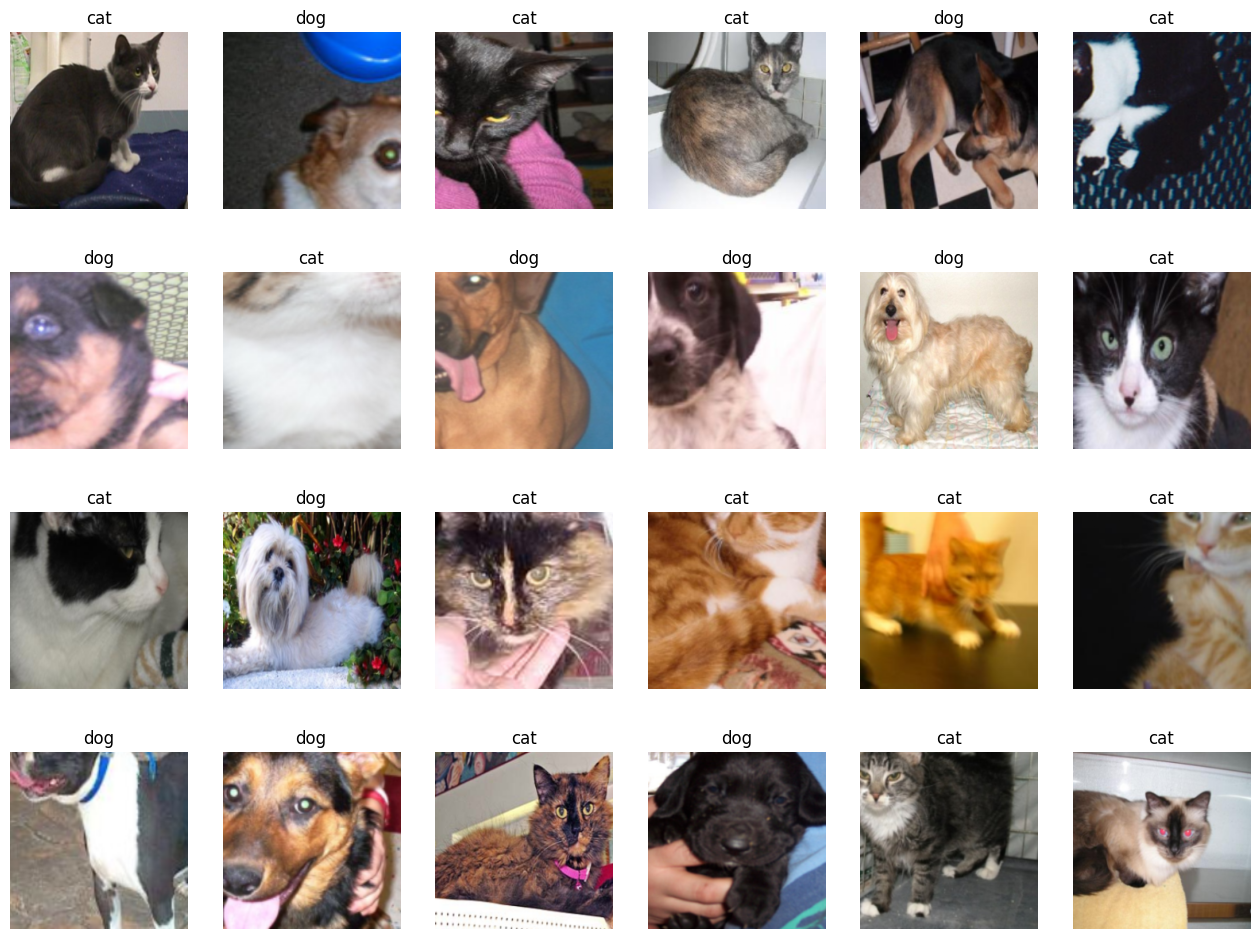

In [4]:
# 학습에 사용될 이미지 출력
import numpy as np

samples, labels = next(iter(train_loader)) # 반복자 사용하려면 iter와 next 필요.
classes = {0:'cat', 1:'dog'}
fig = plt.figure(figsize=(16,24))
for i in range(24):
  a = fig.add_subplot(4, 6, i+1)
  a.set_title(classes[labels[i].item()]) # 레이블 정보를 함께 출력
  a.axis('off')
  a.imshow(np.transpose(samples[i].numpy(), (1,2,0)))
plt.subplots_adjust(bottom=0.2, top=0.6, hspace=0)

In [5]:
resnet18 = models.resnet18(pretrained=True)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 139MB/s]


In [6]:
# 사전 훈련된 모델의 파라미터 학습 유무 지정
def set_parameter_requires_grad(model, feature_extracting=True):
    if feature_extracting:
        for param in model.parameters():
            param.requires_grad = False  # 역전파 중 파라미터들에 대한 변화 계산할 필요 없음.
set_parameter_requires_grad(resnet18)

역전파 중 파라미터들에 대한 변화를 계산할 필요가 없음을 나타냄.

-> 모델의 일부를 고 정하고 나머지를 학습하고자 할 때 requires_grad = False로 설정. 이때 모댈의 일부는 합 성곱층(convolutïonal layer)과 풀링(pooling)층을 의미


In [7]:
# ResNet18에 fc 추가
resnet18.fc = nn.Linear(512,2) # 2는 클래스가 두 개라는 의미

In [8]:
# 모델의 파라미터 값들 확인
for name, param in resnet18.named_parameters():
  if param.requires_grad:
    print(name, param.data)

fc.weight tensor([[-0.0164,  0.0418, -0.0411,  ..., -0.0040, -0.0215, -0.0010],
        [ 0.0277, -0.0067, -0.0117,  ..., -0.0144,  0.0367, -0.0203]])
fc.bias tensor([-0.0401, -0.0035])


In [9]:
# 모델 객체 생성 및 손실 함수 정의
model = models.resnet18(pretrained = True)

for param in model.parameters():
    param.requires_grad = False

model.fc = torch.nn.Linear(512, 2)
for param in model.fc.parameters():
    param.requires_grad = True

optimizer = torch.optim.Adam(model.fc.parameters())
cost = torch.nn.CrossEntropyLoss()
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [10]:
# 모델 학습을 위한 함수 생성
def train_model(model, dataloaders, criterion, optimizer, device, num_epochs=13, is_train=True):
    since = time.time()
    acc_history = []
    loss_history = []
    best_acc = 0.0

    for epoch in range(num_epochs):
        print('Epoch {}/{}'.format(epoch, num_epochs - 1))
        print('-' * 10)

        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in dataloaders:
            inputs = inputs.to(device)
            labels = labels.to(device)

            model.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            _, preds = torch.max(outputs, 1)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        epoch_loss = running_loss / len(dataloaders.dataset)
        epoch_acc = running_corrects.double() / len(dataloaders.dataset)

        print('Loss: {:.4f} Acc: {:.4f}'.format(epoch_loss, epoch_acc))

        if epoch_acc > best_acc:
            best_acc = epoch_acc

        acc_history.append(epoch_acc.item())
        loss_history.append(epoch_loss)
        torch.save(model.state_dict(), os.path.join('./080289/chap05/data/catanddog/', '{0:0=2d}.pth'.format(epoch)))
        print()

    time_elapsed = time.time() - since
    print('Training complete in {:.0f}m {:.0f}s'.format(time_elapsed // 60, time_elapsed % 60))
    print('Best Acc: {:4f}'.format(best_acc))
    return acc_history, loss_history

In [11]:
# 파라미터 학습 결과를 옵티마이저에 전달
params_to_update = []
for name, param in resnet18.named_parameters():
  if param.requires_grad == True:
    params_to_update.append(param)
    print('\t', name)

optimizer = optim.Adam(params_to_update)

	 fc.weight
	 fc.bias


In [12]:
# 모델 학습
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
criterion = nn.CrossEntropyLoss()
train_acc_hist, train_loss_hist = train_model(resnet18, train_loader, criterion, optimizer, device)

Epoch 0/12
----------
Loss: 0.6106 Acc: 0.6883

Epoch 1/12
----------
Loss: 0.3854 Acc: 0.8545

Epoch 2/12
----------
Loss: 0.3178 Acc: 0.8805

Epoch 3/12
----------
Loss: 0.3151 Acc: 0.8701

Epoch 4/12
----------
Loss: 0.3170 Acc: 0.8623

Epoch 5/12
----------
Loss: 0.2048 Acc: 0.9351

Epoch 6/12
----------
Loss: 0.2321 Acc: 0.9117

Epoch 7/12
----------
Loss: 0.2081 Acc: 0.9273

Epoch 8/12
----------
Loss: 0.2831 Acc: 0.8753

Epoch 9/12
----------
Loss: 0.2667 Acc: 0.8831

Epoch 10/12
----------
Loss: 0.2140 Acc: 0.9195

Epoch 11/12
----------
Loss: 0.1759 Acc: 0.9221

Epoch 12/12
----------
Loss: 0.2214 Acc: 0.9117

Training complete in 9m 22s
Best Acc: 0.935065


In [13]:
# 테스트 데이터 호출 및 전처리
test_path = './080289/chap05/data/catanddog/test/'

transform = transforms.Compose(
    [
        transforms.Resize(224),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
    ])
test_dataset = torchvision.datasets.ImageFolder(
    root=test_path,
    transform=transform
)
test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=32,
    num_workers=1,
    shuffle=True
)
print(len(test_dataset))

98


In [14]:
# 테스트 데이터 평가 함수 생성
def eval_model(model, dataloaders, device):
  since = time.time()
  acc_history = []
  best_acc = 0.0

  saved_models = glob.glob('./080289/chap05/data/catanddog/' + '*.pth')
  saved_models.sort()
  print('saved_model', saved_models)

  for model_path in saved_models:
    print('Loading model', model_path)

    model.load_state_dict(torch.load(model_path))
    model.eval()
    model.to(device)
    running_corrects = 0

    for inputs, labels in dataloaders:
      inputs = inputs.to(device)
      labels = labels.to(device)

      with torch.no_grad():
        outputs = model(inputs)

      _, preds = torch.max(outputs.data, 1)
      preds[preds >= 0.5] = 1
      preds[preds < 0.5] = 0
      running_corrects += preds.eq(labels).int().sum()

    epoch_acc = running_corrects.double() / len(dataloaders.dataset)
    print('Acc: {:.4f}'.format(epoch_acc))

    if epoch_acc > best_acc:
      best_acc = epoch_acc

    acc_history.append(epoch_acc.item())
    print()

  time_elapsed = time.time() - since
  print('Validation complete in {:.0f}m {:.0f}s'.format(time_elapsed // 60, time_elapsed % 60))
  print('Best Acc: {:4f}'.format(best_acc))

  return acc_history

In [15]:
# 테스트 데이터를 평가 함수에 적용
val_acc_hist = eval_model(resnet18, test_loader, device)

saved_model ['./080289/chap05/data/catanddog/00.pth', './080289/chap05/data/catanddog/01.pth', './080289/chap05/data/catanddog/02.pth', './080289/chap05/data/catanddog/03.pth', './080289/chap05/data/catanddog/04.pth', './080289/chap05/data/catanddog/05.pth', './080289/chap05/data/catanddog/06.pth', './080289/chap05/data/catanddog/07.pth', './080289/chap05/data/catanddog/08.pth', './080289/chap05/data/catanddog/09.pth', './080289/chap05/data/catanddog/10.pth', './080289/chap05/data/catanddog/11.pth', './080289/chap05/data/catanddog/12.pth']
Loading model ./080289/chap05/data/catanddog/00.pth
Acc: 0.8776

Loading model ./080289/chap05/data/catanddog/01.pth
Acc: 0.9082

Loading model ./080289/chap05/data/catanddog/02.pth
Acc: 0.9490

Loading model ./080289/chap05/data/catanddog/03.pth
Acc: 0.8980

Loading model ./080289/chap05/data/catanddog/04.pth
Acc: 0.9694

Loading model ./080289/chap05/data/catanddog/05.pth
Acc: 0.9490

Loading model ./080289/chap05/data/catanddog/06.pth
Acc: 0.9592


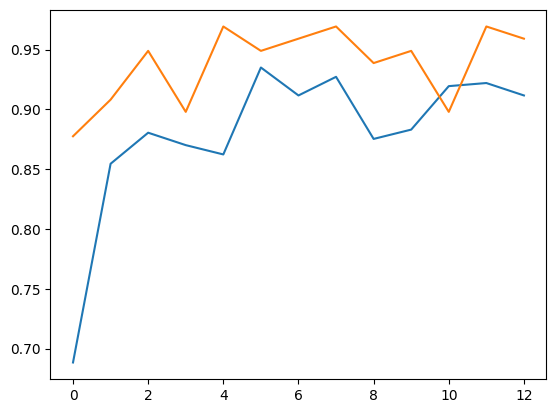

In [16]:
# 훈련과 테스트 데이터의 정확도를 그래프로 확인
plt.plot(train_acc_hist)
plt.plot(val_acc_hist)
plt.show()

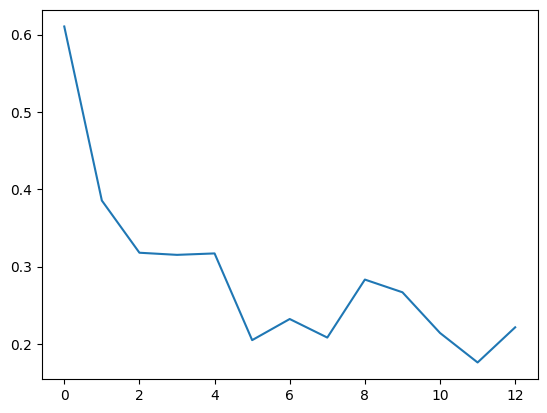

In [17]:
# 훈련 데이터의 오차에 대한 그래프 확인
plt.plot(train_loss_hist)
plt.show()

In [18]:
# 예측 이미지 출력을 위한 전처리 함수
def im_convert(tensor):
  image = tensor.clone().detach().numpy() # clone은 기존 텐서의 내용을 복사한 텐서 생성. detach는 기존 텐서에서 기울기가 전파되지 않는 텐서.
  image = image.transpose(1,2,0)
  image = image * (np.array((0.5,0.5,0.5)))
  image = image.clip(0,1) # 입력 값이 주어진 범위를 벗어날 때 입력 값을 특정 범위로 제한시키기 위해 사용. 즉 clip(0,1)은 image 데이터를 0과 1 사이의 값으로 제한.
  return image

**계산 그래프**

계산 과정을 그래프로 나타낸 것.

그래프는 여러 개의 노드와 그 노드들을 연결하는 선인 에지(edge)로 구성됨.

계산 그래프를 사용하는 두 가지 이유
- 국소적 계산이 가능
- 역전파를 통한 미분 계산이 편리

**연쇄 법칙**

두 개 이상의 함수가 결합된 함수.

합성 함수의 미분법을 연쇄 법칙 혹은 체인룰이라고 함.

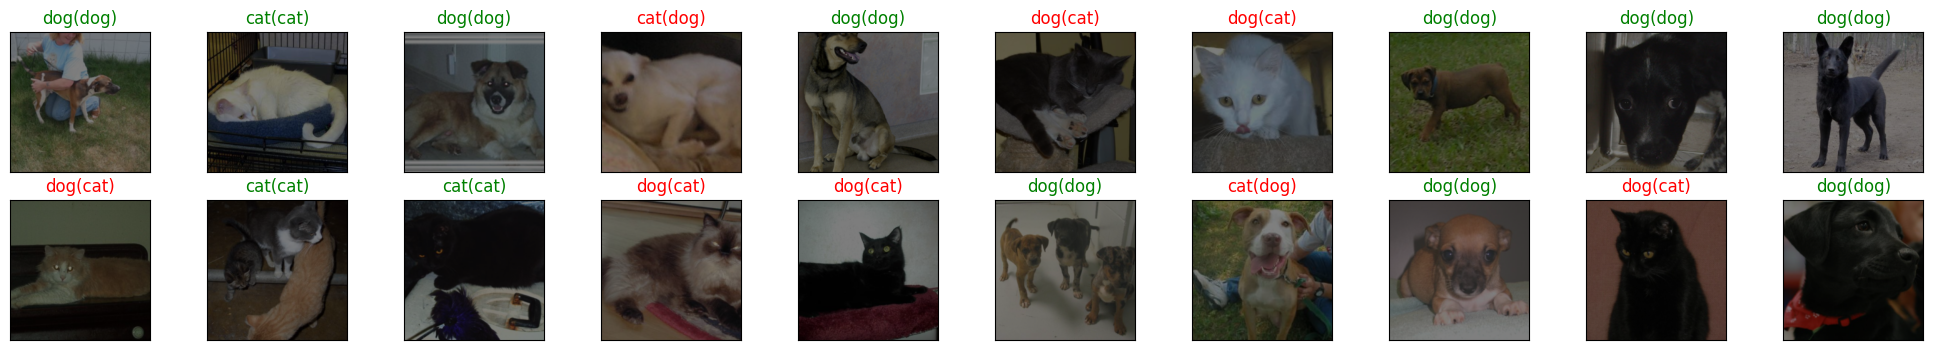

<Figure size 640x480 with 0 Axes>

In [19]:
# 개와 고양이 예측 결과 출력
classes = {0:'cat', 1:'dog'}

dataiter = iter(test_loader) # 테스트 데이터셋을 가져옴
images, labels = next(dataiter)
output = model(images)
_, preds = torch.max(output, 1)

fig = plt.figure(figsize=(25,4))
for idx in np.arange(20):
  ax = fig.add_subplot(2, 10, idx+1, xticks=[], yticks=[]) # 2행 10열. tick삭제하겠다~
  plt.imshow(im_convert(images[idx]))
  a.set_title(classes[labels[i].item()]) # 0과 1 중 어떤 값을 갖는지 판별하겠다.
  ax.set_title('{}({})'.format(str(classes[preds[idx].item()]), str(classes[labels[idx].item()])), color=('green' if preds[idx]==labels[idx] else 'red'))
plt.show()
plt.subplots_adjust(bottom=0.2, top=0.6, hspace=0)